In [23]:
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

In [24]:
data = pd.read_csv("C:/Users/DIBYAJIT/OneDrive/Desktop/Top Mentor/Machine Learning/2nd November Files/Multi Linear Regression - Assignment -3_4/50_Startups.csv")
data.head(3)

,R&D Spend,Administration,Marketing Spend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39


In [25]:
data.isnull().sum()

R&D Spend          0
Administration     0
Marketing Spend    0
State              0
Profit             0
dtype: int64

In [26]:
data.shape

(50, 5)

<Axes: ylabel='R&D Spend'>

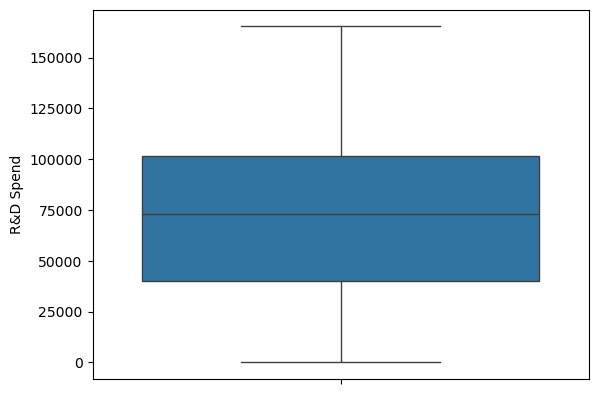

In [27]:
sns.boxplot (data['R&D Spend'])

<Axes: ylabel='Administration'>

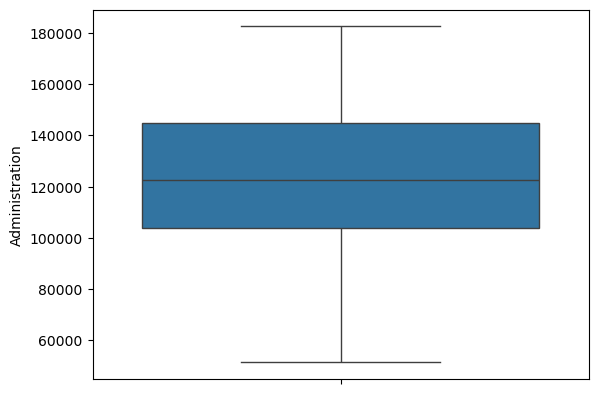

In [28]:
sns.boxplot (data['Administration'])

<Axes: ylabel='Marketing Spend'>

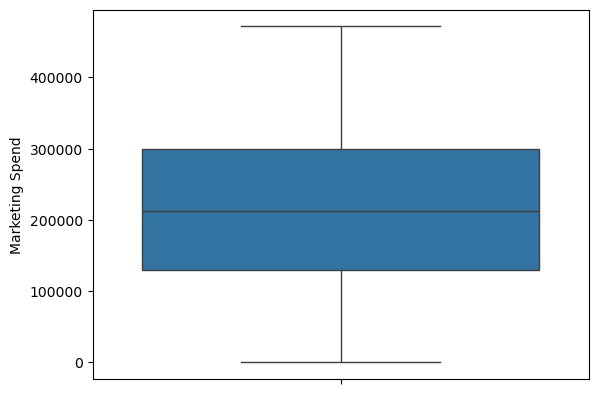

In [29]:
sns.boxplot (data['Marketing Spend'])

In [30]:
X = data [['R&D Spend', 'Administration', 'Marketing Spend']]
y = data ['Profit']



In [43]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state = 42)

In [44]:
X_train.shape

(40, 3)

In [45]:
X_test.shape

(10, 3)

In [46]:
y_train.shape

(40,)

In [47]:
y_test.shape

(10,)

In [32]:
model = LinearRegression()

In [38]:
model.fit(X_train,y_train)
pred_profit = model.predict(X_test)


In [41]:
round (r2_score(y_test,pred_profit)*100, 6)

90.006531

In [42]:
from sklearn.neighbors import KNeighborsRegressor

In [49]:
knn = KNeighborsRegressor(n_neighbors=3)

In [50]:
knn.fit(X_train,y_train)

KNeighborsRegressor(n_neighbors=3)

In [51]:
pred_profit2 = knn.predict (X_test)
pred_profit2

array([132831.83      ,  85169.13333333, 102346.74666667,  42333.37      ,
       120857.61666667,  42333.37      , 104279.68666667, 104279.68666667,
        77480.95666667,  59173.01333333])

In [52]:
r2_score (y_test,pred_profit2)

0.3756829431509314

In [53]:
#how to select the value of n?
# it is the range from 1 to the (sqrt of number of rows).
import numpy as np

In [60]:
r = int (round (np.sqrt(data.shape[0]),0))
r

7

In [71]:

for i in (range (1, r+1)):
    knn = KNeighborsRegressor(n_neighbors=i)
    knn.fit(X_train,y_train)
    pred_profit2 = knn.predict (X_test)
    acc = r2_score (y_test,pred_profit2)
    err = 1 - acc
    print ("N number: ", i)
    print ("Accuracyr: ", acc*100)
    print ("Error: " , err*100)

N number:  1
Accuracyr:  43.36590437439432
Error:  56.63409562560568
N number:  2
Accuracyr:  57.335295885472505
Error:  42.664704114527495
N number:  3
Accuracyr:  37.56829431509314
Error:  62.43170568490686
N number:  4
Accuracyr:  42.00001362812983
Error:  57.99998637187017
N number:  5
Accuracyr:  29.490111313370658
Error:  70.50988868662934
N number:  6
Accuracyr:  35.217050342485166
Error:  64.78294965751483
N number:  7
Accuracyr:  40.55155415913833
Error:  59.44844584086167


In [ ]:
# we are gonna choose liearn regression for its high accuracy and low error